In [ ]:
#%pip install tensorflow sacrebleu

In [1]:
import tensorflow as tf

In [ ]:
# just repeat what it is done in task 3
english_file = "../data/preprocessed_10_percent.en"
dutch_file = "../data/preprocessed_10_percent.nl"

sentence_pairs = []

with open(english_file, encoding='utf-8') as english_data, open(dutch_file, encoding='utf-8') as dutch_data:
    for english_line, dutch_line in zip(english_data, dutch_data):
        sentence_pairs.append((english_line.strip(), dutch_line.strip()))

print('sentence pairs:', len(sentence_pairs))

sentence pairs: 197853


In [3]:
# repeating what it is done in task 3
import random

random.seed(42)
random.shuffle(sentence_pairs)

total_size = len(sentence_pairs)
test_size = int(total_size * 0.20)
validation_size = int(total_size * 0.10)
training_size = total_size - test_size - validation_size

training_pairs = sentence_pairs[:training_size]
validation_pairs = sentence_pairs[training_size:training_size + validation_size]
test_pairs = sentence_pairs[training_size + validation_size:]

print('training pairs:', len(training_pairs))
print('validation pairs:', len(validation_pairs))
print('test pairs:', len(test_pairs))

training pairs: 138498
validation pairs: 19785
test pairs: 39570


In [4]:
max_english_length = 55
max_dutch_length = 57

In [5]:
# same function in task 3
def process_sentences(pairs):
    english_sentences = []
    dutch_sentences = []
    for english_sentence, dutch_sentence in pairs:
        english_sentences.append(english_sentence)
        dutch_sentences.append('startmark ' + dutch_sentence + ' endmark')
    return english_sentences, dutch_sentences

train_english, train_dutch = process_sentences(training_pairs)
val_english, val_dutch = process_sentences(validation_pairs)
test_english, test_dutch = process_sentences(test_pairs)

In [6]:
# similar vectorizer setup as task 3
max_vocab_size = 20000

english_vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=max_vocab_size,
    standardize=None,
    split='whitespace',
    output_mode='int',
    output_sequence_length=max_english_length)

dutch_vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=max_vocab_size,
    standardize=None,
    split='whitespace',
    output_mode='int',
    output_sequence_length=max_dutch_length)

english_vectorizer.adapt(train_english)
dutch_vectorizer.adapt(train_dutch)

english_vocab_size = len(english_vectorizer.get_vocabulary())
dutch_vocab_size = len(dutch_vectorizer.get_vocabulary())

print('english vocab:', english_vocab_size)
print('dutch vocab:', dutch_vocab_size)

english vocab: 20000
dutch vocab: 20000


In [ ]:
# the decoder input is shifted by one position against the decoder target

encoder_inputs = english_vectorizer(train_english)
dutch_sequences = dutch_vectorizer(train_dutch)
decoder_inputs = dutch_sequences[:, :-1]
decoder_targets = dutch_sequences[:, 1:]

val_encoder_inputs = english_vectorizer(val_english)
val_dutch_sequences = dutch_vectorizer(val_dutch)
val_decoder_inputs = val_dutch_sequences[:, :-1]
val_decoder_targets = val_dutch_sequences[:, 1:]

In [7]:
# same encoder-decoder as in task 3, the only change is the additive attention
# layer between the encoder outputs and the decoder outputs

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(42)

embedding_size = 128
hidden_size = 256

# the encoder has to return all outputs now, the attention layer needs them
encoder_input = tf.keras.Input(shape=(max_english_length,), name="encoder_input")
encoder_embedding = tf.keras.layers.Embedding(english_vocab_size, embedding_size, mask_zero=True)(encoder_input)
encoder_gru = tf.keras.layers.GRU(hidden_size, return_sequences=True, return_state=True)
encoder_outputs, encoder_state = encoder_gru(encoder_embedding)

decoder_input = tf.keras.Input(shape=(max_dutch_length - 1,), name="decoder_input")
decoder_embedding_layer = tf.keras.layers.Embedding(dutch_vocab_size, embedding_size, mask_zero=True)
decoder_embedding = decoder_embedding_layer(decoder_input)
decoder_gru = tf.keras.layers.GRU(hidden_size, return_sequences=True, return_state=True)
decoder_outputs, _ = decoder_gru(decoder_embedding, initial_state=encoder_state)

attention_layer = tf.keras.layers.AdditiveAttention()
context, _ = attention_layer([decoder_outputs, encoder_outputs], return_attention_scores=True)
decoder_combined = tf.keras.layers.Concatenate()([context, decoder_outputs])

decoder_dense = tf.keras.layers.Dense(dutch_vocab_size)
word_predictions = decoder_dense(decoder_combined)

attention_model = tf.keras.Model([encoder_input, decoder_input], word_predictions)
attention_model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 55)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_input       │ (None, 56)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 55, 128)   │  2,560,000 │ encoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 55)        │          0 │ encoder_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_1         │ (None, 56, 128)   │  2,560,000 │ decoder_input[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru (GRU)           │ [(None, 55, 256), │    296,448 │ embedding[0][0],  │
│                     │ (None, 256)]      │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ gru_1 (GRU)         │ [(None, 56, 256), │    296,448 │ embedding_1[0][0… │
│                     │ (None, 256)]      │            │ gru[0][1]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ additive_attention  │ [(None, 56, 256), │        256 │ gru_1[0][0],      │
│ (AdditiveAttention) │ (None, 56, 55)]   │            │ gru[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 56, 512)   │          0 │ additive_attenti… │
│ (Concatenate)       │                   │            │ gru_1[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 56, 20000) │ 10,260,000 │ concatenate[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 15,973,152 (60.93 MB)

 Trainable params: 15,973,152 (60.93 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# optimizer, loss and metric

attention_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.002, clipnorm=1.0),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='word_accuracy')])

In [11]:
# training on all 138498 training pairs

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=1,
    restore_best_weights=True)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    'attention_en_to_nl.weights.h5',
    monitor='val_loss',
    save_best_only=True,
    save_weights_only=True)

history = attention_model.fit(
    [encoder_inputs, decoder_inputs],
    decoder_targets,
    validation_data=([val_encoder_inputs, val_decoder_inputs], val_decoder_targets),
    batch_size=32,
    epochs=5,
    callbacks=[early_stopping, checkpoint])

Epoch 1/5
4329/4329 ━━━━━━━━━━━━━━━━━━━━ 2513s 580ms/step - loss: 4.3460 - word_accuracy: 0.2978 - val_loss: 3.6630 - val_word_accuracy: 0.3591
Epoch 2/5
4329/4329 ━━━━━━━━━━━━━━━━━━━━ 2408s 556ms/step - loss: 3.1200 - word_accuracy: 0.4166 - val_loss: 2.9995 - val_word_accuracy: 0.4364
Epoch 3/5
4329/4329 ━━━━━━━━━━━━━━━━━━━━ 2476s 572ms/step - loss: 2.5422 - word_accuracy: 0.4778 - val_loss: 2.9660 - val_word_accuracy: 0.4415
Epoch 4/5
4329/4329 ━━━━━━━━━━━━━━━━━━━━ 2338s 540ms/step - loss: 2.2554 - word_accuracy: 0.5147 - val_loss: 3.0099 - val_word_accuracy: 0.4424


In [9]:
# inference models
# the weights are loaded here, so this cell also works when the training cell above is skipped

attention_model.load_weights('attention_en_to_nl.weights.h5')

encoder_inference_model = tf.keras.Model(encoder_input, [encoder_outputs, encoder_state])

step_input = tf.keras.Input(shape=(1,), dtype='int64')
state_input = tf.keras.Input(shape=(hidden_size,))
encoder_outputs_input = tf.keras.Input(shape=(max_english_length, hidden_size))
source_mask_input = tf.keras.Input(shape=(max_english_length,), dtype='bool')

step_embedding = decoder_embedding_layer(step_input)
step_output, step_state = decoder_gru(step_embedding, initial_state=state_input)

# during training keras passes the padding mask into the attention layer automatically,
# here it has to be handed over by hand, otherwise the attention also looks at the padding
step_context, step_scores = attention_layer(
    [step_output, encoder_outputs_input],
    mask=[None, source_mask_input],
    return_attention_scores=True)

step_combined = tf.keras.layers.Concatenate()([step_context, step_output])
step_predictions = decoder_dense(step_combined)

decoder_inference_model = tf.keras.Model(
    [step_input, state_input, encoder_outputs_input, source_mask_input],
    [step_predictions, step_state, step_scores])

/Users/bensc/Documents/MI-Master/FS_1/NLP/Projects/project_2/.venv/lib/python3.11/site-packages/keras/src/saving/saving_lib.py:843: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 24 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [10]:
dutch_vocabulary = dutch_vectorizer.get_vocabulary()

start_token_id = dutch_vocabulary.index('startmark')
end_token_id = dutch_vocabulary.index('endmark')

# greedy decoding, one dutch word per step

def translate_sentences(english_sentences):
    english_sequences = english_vectorizer(english_sentences)
    source_mask = tf.not_equal(english_sequences, 0)
    encoder_outputs_value, states = encoder_inference_model(english_sequences, training=False)
    current_words = tf.fill([len(english_sentences), 1], tf.constant(start_token_id, dtype=tf.int64))

    generated_word_ids = []
    for step in range(max_dutch_length - 1):
        word_scores, states, _ = decoder_inference_model(
            [current_words, states, encoder_outputs_value, source_mask], training=False)
        next_word_ids = tf.argmax(word_scores[:, 0, :], axis=-1, output_type=tf.int64)
        generated_word_ids.append(next_word_ids.numpy())
        current_words = tf.expand_dims(next_word_ids, axis=1)

    translations = []
    for sentence_number in range(len(english_sentences)):
        translated_words = []
        for word_ids in generated_word_ids:
            word_id = int(word_ids[sentence_number])
            if word_id == end_token_id or word_id == 0:
                break
            translated_words.append(dutch_vocabulary[word_id])
        translations.append(' '.join(translated_words))
    return translations

In [ ]:
# test
# translate_sentences(test_english[:5])


/Users/bensc/Documents/MI-Master/FS_1/NLP/Projects/project_2/.venv/lib/python3.11/site-packages/keras/src/layers/layer.py:1039: UserWarning: Layer 'functional_2' (of type Functional) was passed an input with a mask attached to it. However, this layer does not support masking and will therefore destroy the mask information. Downstream layers will not see the mask.
  warnings.warn(


['ik wil ook u, mevrouw de voorzitter, ook bedanken.',
 'niemand zou een abortus willen zijn.',
 'hartelijk dank, mijnheer de fungerend voorzitter.',
 'wij moeten ook de onderhandelingen over de bijdrage van lissabon [UNK] het welslagen van de top op het gebied van de werkgelegenheid.',
 'wij steunen het doel van dit verslag dat het doel van de eu op het gebied van ontwikkelingssamenwerking en [UNK] in de eu en de [UNK]']

In [12]:
# translate the complete test set in batches

import json

test_predictions = []
evaluation_batch_size = 500

for start_position in range(0, len(test_english), evaluation_batch_size):
    batch_sentences = test_english[start_position:start_position + evaluation_batch_size]
    test_predictions.extend(translate_sentences(batch_sentences))
    print('translated', min(start_position + evaluation_batch_size, len(test_english)), 'of', len(test_english))

    # safety dump in case kernel crashes
    json.dump(test_predictions, open('task4_test_predictions.json', 'w'))

translated 500 of 39570
translated 1000 of 39570
translated 1500 of 39570
translated 2000 of 39570
translated 2500 of 39570
translated 3000 of 39570
translated 3500 of 39570
translated 4000 of 39570
translated 4500 of 39570
translated 5000 of 39570
translated 5500 of 39570
translated 6000 of 39570
translated 6500 of 39570
translated 7000 of 39570
translated 7500 of 39570
translated 8000 of 39570
translated 8500 of 39570
translated 9000 of 39570
translated 9500 of 39570
translated 10000 of 39570
translated 10500 of 39570
translated 11000 of 39570
translated 11500 of 39570
translated 12000 of 39570
translated 12500 of 39570
translated 13000 of 39570
translated 13500 of 39570
translated 14000 of 39570
translated 14500 of 39570
translated 15000 of 39570
translated 15500 of 39570
translated 16000 of 39570
translated 16500 of 39570
translated 17000 of 39570
translated 17500 of 39570
translated 18000 of 39570
translated 18500 of 39570
translated 19000 of 39570
translated 19500 of 39570
transl

In [13]:
import sacrebleu

# the references are the dutch test sentences without the markers
test_references = [dutch_sentence for english_sentence, dutch_sentence in test_pairs]

test_bleu = sacrebleu.corpus_bleu(test_predictions, [test_references]).score
test_chrf = sacrebleu.corpus_chrf(test_predictions, [test_references]).score

print('test BLEU:', round(test_bleu, 2))
print('test chrF:', round(test_chrf, 2))

test BLEU: 11.59
test chrF: 33.55


In [14]:
# a few sample translations

for sentence_number in range(5):
    print('english:', test_english[sentence_number])
    print('reference:', test_references[sentence_number])
    print('attention model:', test_predictions[sentence_number])
    print()

english: i would also like to thank you, minister.
reference: ik wil ook graag u, mijnheer de minister, bedanken.
attention model: ik wil ook u, mevrouw de voorzitter, ook bedanken.

english: no one would wish an abortion on anyone.
reference: niemand wenst een ander abortus toe.
attention model: niemand zou een abortus willen zijn.

english: thank you very much, mr president-in-office.
reference: ik dank u, mijnheer de fungerend voorzitter van de raad.
attention model: hartelijk dank, mijnheer de fungerend voorzitter.

english: we should also judge the success of the lisbon summit on the contribution it makes to achieving this goal.
reference: als we de top van lissabon beoordelen, moeten we ook zien in hoeverre we dichter bij dit doel zijn gekomen.
attention model: wij moeten ook de onderhandelingen over de bijdrage van lissabon [UNK] het welslagen van de top op het gebied van de werkgelegenheid.

english: we support the objective of this report for eu policy to be consistent with th

In [15]:
import numpy as np

# translate a single sentence and keep the attention weights of every decoding step

def translate_with_attention(sentence):
    english_sequence = english_vectorizer([sentence])
    source_mask = tf.not_equal(english_sequence, 0)
    encoder_outputs_value, states = encoder_inference_model(english_sequence, training=False)
    current_word = tf.fill([1, 1], tf.constant(start_token_id, dtype=tf.int64))

    translated_words = []
    step_weights = []

    for step in range(max_dutch_length - 1):
        word_scores, states, scores = decoder_inference_model(
            [current_word, states, encoder_outputs_value, source_mask], training=False)
        next_word_id = int(tf.argmax(word_scores[0, 0, :]))
        if next_word_id == end_token_id or next_word_id == 0:
            break
        translated_words.append(dutch_vocabulary[next_word_id])
        step_weights.append(scores[0, 0, :].numpy())
        current_word = tf.fill([1, 1], tf.constant(next_word_id, dtype=tf.int64))

    return translated_words, np.array(step_weights)

sample_sentence = test_english[0]
source_words = sample_sentence.split()
target_words, attention_weights = translate_with_attention(sample_sentence)

print('source:', sample_sentence)
print('translation:', ' '.join(target_words))

source: i would also like to thank you, minister.
translation: ik wil ook u, mevrouw de voorzitter, ook bedanken.


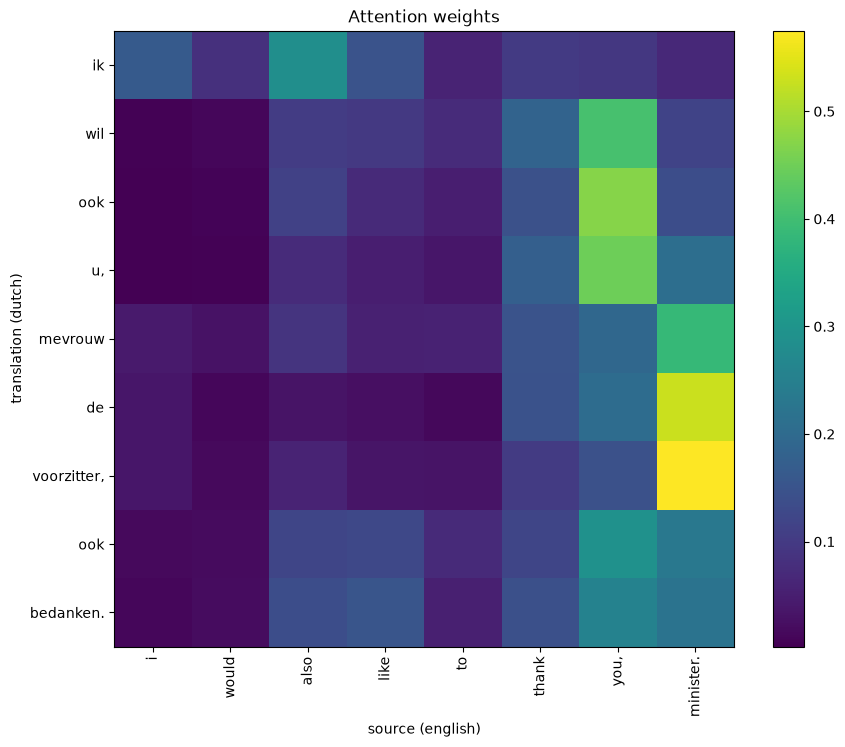

In [16]:
import matplotlib.pyplot as plt

# only the real source positions, the rest is padding
weights = attention_weights[:, :len(source_words)]

plt.figure(figsize=(10, 8))
plt.imshow(weights, cmap='viridis', aspect='auto')
plt.xticks(range(len(source_words)), source_words, rotation=90)
plt.yticks(range(len(target_words)), target_words)
plt.xlabel('source (english)')
plt.ylabel('translation (dutch)')
plt.title('Attention weights')
plt.colorbar()

plt.savefig('task4_figure1.png', dpi=300, bbox_inches='tight')
plt.show()